###Analysis of the log written by **`lab9_gyro.qrs`**:

1. **Offset** $b_0$ — mean rate while the robot is still, $b_0(T)$ curve, own `calibrate_gyro()`
2. **Drift** $d$ and **heading integrals** — how fast the offset changes, how much heading error it causes
3. **Measurement limits** $\pm\omega_{max}$ — the largest rate the gyro reports before it clips
4. **Noise** $\sigma$ — random part of the reading at rest

In [1]:
LOG_PATH = "lab9_gyro_78.csv"      # raw log from the robot
T_CAL_BASELINE = 30.0           # §1 baseline calibration window, s
HEADING_TOL_DEG = 1.0           # §1 allowed heading error from a wrong b0 after 3 min, deg

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import cumulative_trapezoid as cumtrapz
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

try:  # Colab: ask for the file if it is not there
    from google.colab import files
    if not os.path.exists(LOG_PATH):
        LOG_PATH = list(files.upload().keys())[0]
except ImportError:
    pass

## 0. Load the log and check the clock
Columns: `t_us` (gyro timestamp, µs), `t_ms` (script clock, ms), `gz_cal` (rate, mdeg/s), `encL`, `encR`, `u`, `phase` (0 static, 1 sin, 2 rect, 3 rest).

**Time base.** The gyro timestamp `t_us` is used only if it never goes backwards **and** covers the same total time as the script clock `t_ms` (within 2 %). Otherwise `t_ms` is used.
Repeated gyro samples (same `t_us` twice) are removed only when `t_us` is trusted.
Always check the printout below: the static phase must last ≈ 180 s (≈ 10 s for the quick test).

,t_us,t_ms,gz_cal,encL,encR,u,phase
0,0,69,376,0,0,0,0
1,530,164,525,0,0,0,0
2,815,230,428,0,0,0,0
3,1059,294,525,0,0,0,0
4,1303,355,490,0,0,0,0


rows: 4006
total time from t_ms: 254.97 s
total time from t_us: 1.00 s  (assuming µs)  never goes back: True
-> time base: t_ms (script clock). t_us does NOT match the real time (t_ms span / t_us span = 256), so it is not a µs timestamp on this robot.


,count,min,max,duration_s
phase,,,,
0 static,2827,0.00,179.92,179.92
1 sin,562,179.99,215.89,35.90
2 rect,569,215.95,251.93,35.98
3 rest,48,251.99,254.97,2.97


static: 2827 samples, 179.9 s, 16.1 Hz | rotation: 1179 samples


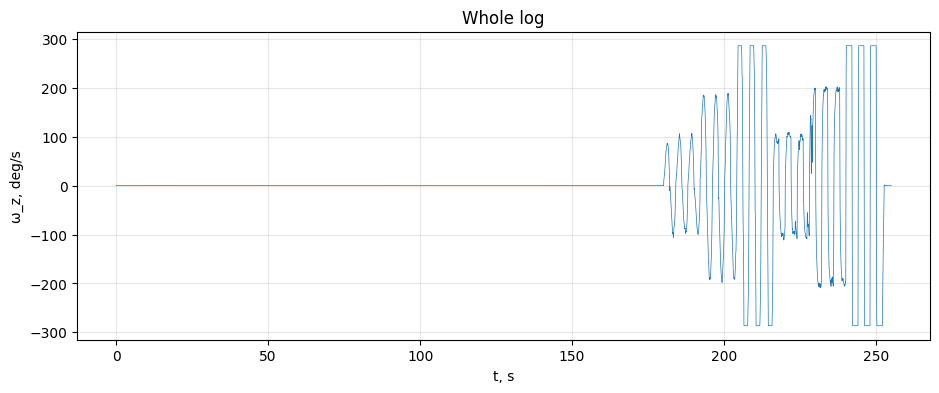

In [2]:
log = pd.read_csv(LOG_PATH, skipinitialspace=True)
log["phase"] = np.floor(log["phase"].astype(float) + 1e-9).astype(int)   # boundary sample x.5 -> earlier phase
display(log.head())

# --- which clock can we trust?
t_us_raw = log["t_us"].astype(float).values
span_ms = (log["t_ms"].iloc[-1] - log["t_ms"].iloc[0]) / 1e3      # s, script clock
span_us = (t_us_raw[-1] - t_us_raw[0]) / 1e6                       # s, if t_us really is in µs
t_us_ok = bool(np.all(np.diff(t_us_raw) >= 0)) and abs(span_us - span_ms) < 0.02 * span_ms + 0.05
print("rows: %d" % len(log))
print("total time from t_ms: %.2f s" % span_ms)
print("total time from t_us: %.2f s  (assuming µs)  never goes back: %s" % (span_us, bool(np.all(np.diff(t_us_raw) >= 0))))

if t_us_ok:
    n0 = len(log)
    log = log.drop_duplicates("t_us").reset_index(drop=True)
    log["t"] = (log["t_us"] - log["t_us"].iloc[0]) / 1e6
    print("-> time base: t_us (gyro timestamp); %d repeated gyro samples removed" % (n0 - len(log)))
else:
    log["t"] = (log["t_ms"] - log["t_ms"].iloc[0]) / 1e3
    ratio = span_ms / span_us if span_us != 0 else float("nan")
    print("-> time base: t_ms (script clock). t_us does NOT match the real time "
          "(t_ms span / t_us span = %.4g), so it is not a µs timestamp on this robot." % ratio)
log["omega_z"] = log["gz_cal"] / 1000.0          # deg/s

# --- how long did each phase last?
dur = log.groupby("phase")["t"].agg(["count", "min", "max"])
dur["duration_s"] = dur["max"] - dur["min"]
dur.index = dur.index.map({0: "0 static", 1: "1 sin", 2: "2 rect", 3: "3 rest"})
display(dur.round(2))

static = log[log.phase == 0]
t_st = (static["t"] - static["t"].iloc[0]).values
omega_st = static["omega_z"].values
fs = 1.0 / np.median(np.diff(t_st))
rot = log[log.phase >= 1]
if t_st[-1] < 5:
    raise ValueError("The static phase is only %.2f s long (expected ~180 s, ~10 s for the quick test). "
                     "Check the table above: the 'phase' or the time columns of this log are wrong." % t_st[-1])

print("static: %d samples, %.1f s, %.1f Hz | rotation: %d samples" % (len(static), t_st[-1], fs, len(rot)))
plt.plot(log.t, log.omega_z, lw=0.5); plt.xlabel("t, s"); plt.ylabel("ω_z, deg/s"); plt.title("Whole log"); plt.show()

## 1. Offset $b_0$
The robot is still, so the true rate is 0: the mean reading is the offset.
* $b_0$ = mean of the first 30 s, standard error $\sigma/\sqrt N$.
* $b_0(T)$ for $T$ = 1, 2, 5, 10, 20, 30 s. Where the curve stops moving is the **recommended calibration time** `T_cal_rec`.
* "Stops moving" is measured with a band, in **deg/s**: an offset error $\delta b$ gives a heading error $\delta b \cdot 180$ s after 3 min. To keep that below `HEADING_TOL_DEG` = 1°, $\delta b$ must be below `tol` = 1/180 ≈ 0.0056 deg/s.
  `T_cal_rec` is the first $T$ from which $b_0(T)$ stays inside $b_0(60\,\mathrm{s}) \pm$ `tol` **and** its own uncertainty $2\cdot SE$ is smaller than `tol`.

b0 (first 30 s) = 0.4588 ± 0.0035 deg/s


,T_s,b0_deg_s,SE_deg_s
0,1,0.46181,0.01651
1,2,0.45903,0.01310
2,5,0.47581,0.00927
3,10,0.46399,0.00627
4,20,0.45429,0.00443
5,30,0.45879,0.00348


recommended calibration time T_cal_rec = 44.5 s
tolerance band: b0(60 s) ± 0.0056 deg/s  (an offset error of 0.0056 deg/s gives 1.0° heading error after 180 s)


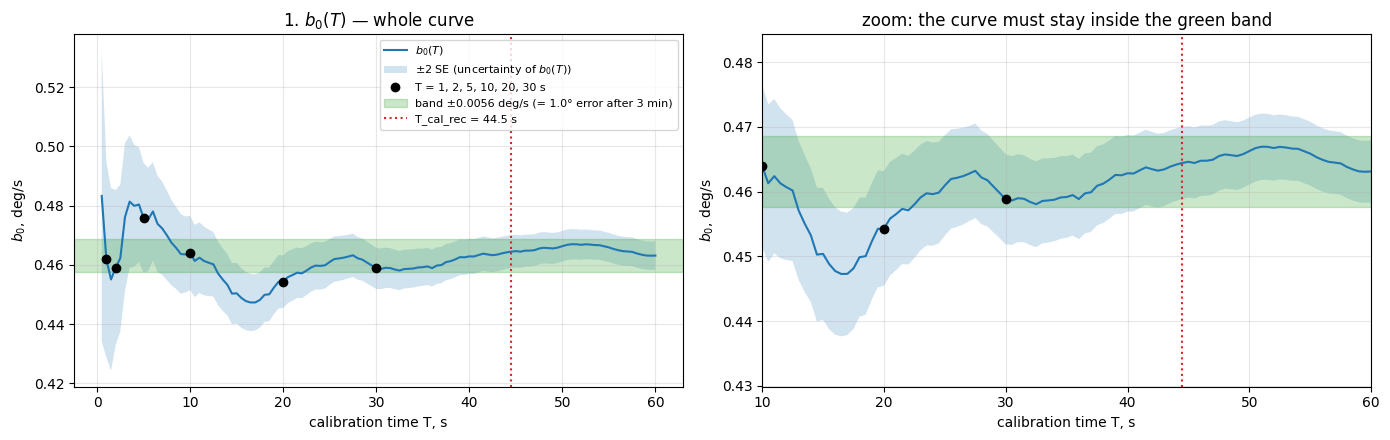

In [3]:
def b0_window(T):
    x = omega_st[t_st <= T]
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))

b0, b0_se = b0_window(T_CAL_BASELINE)
print("b0 (first %.0f s) = %.4f ± %.4f deg/s" % (T_CAL_BASELINE, b0, b0_se))
display(pd.DataFrame([dict(T_s=T, b0_deg_s=b0_window(T)[0], SE_deg_s=b0_window(T)[1]) for T in [1, 2, 5, 10, 20, 30]]).round(5))

tol = HEADING_TOL_DEG / 180.0                     # deg/s: b0 error that gives HEADING_TOL_DEG after 180 s
T_grid = np.arange(0.5, min(60.0, t_st[-1]) + 1e-9, 0.5)
b0_T = np.array([b0_window(T)[0] for T in T_grid])
se_T = np.array([b0_window(T)[1] for T in T_grid])
b0_ref = b0_T[-1]                                      # longest window = best estimate
ok = (np.abs(b0_T - b0_ref) < tol) & (2 * se_T < tol)  # curve inside the band AND its own uncertainty small enough
i_rec = next((i for i in range(len(ok)) if ok[i:].all()), None)
if i_rec is None:
    i_rec = len(T_grid) - 1
    print("b0(T) never settles within the tolerance -> using the longest window; consider a larger HEADING_TOL_DEG")
T_cal_rec = float(T_grid[i_rec])
print("recommended calibration time T_cal_rec = %.1f s" % T_cal_rec)

print("tolerance band: b0(%.0f s) ± %.4f deg/s  (an offset error of %.4f deg/s gives %.1f° heading error after 180 s)"
      % (T_grid[-1], tol, tol, HEADING_TOL_DEG))

T_readme = [1, 2, 5, 10, 20, 30]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a in ax:
    a.plot(T_grid, b0_T, label="$b_0(T)$")
    a.fill_between(T_grid, b0_T - 2 * se_T, b0_T + 2 * se_T, alpha=0.2, label="±2 SE (uncertainty of $b_0(T)$)")
    a.plot(T_readme, [b0_window(T)[0] for T in T_readme], "ko", label="T = 1, 2, 5, 10, 20, 30 s")
    a.axhspan(b0_ref - tol, b0_ref + tol, alpha=0.25, color="C2",
              label="band ±%.4f deg/s (= %.1f° error after 3 min)" % (tol, HEADING_TOL_DEG))
    a.axvline(T_cal_rec, color="C3", ls=":", label="T_cal_rec = %.1f s" % T_cal_rec)
    a.set_xlabel("calibration time T, s"); a.set_ylabel("$b_0$, deg/s")
ax[0].set_title("1. $b_0(T)$ — whole curve"); ax[0].legend(fontsize=8)
zoom = T_grid >= min(T_cal_rec, 10.0)                 # zoom on the part where the curve settles
lo = min((b0_T - 2 * se_T)[zoom].min(), b0_ref - tol); hi = max((b0_T + 2 * se_T)[zoom].max(), b0_ref + tol)
ax[1].set_xlim(T_grid[zoom][0], T_grid[-1]); ax[1].set_ylim(lo - 0.2 * (hi - lo), hi + 0.2 * (hi - lo))
ax[1].set_title("zoom: the curve must stay inside the green band")
plt.tight_layout(); plt.show()

### Own calibration method `calibrate_gyro(log)`
1. take the first `T_cal` seconds of the static phase (default: `T_cal_rec`, at least 10 s);
2. throw away spikes: readings further than 4·MAD from the median (a bump of the table);
3. return the mean of the rest.

In [4]:
def calibrate_gyro(log, T_cal=None, k_mad=4.0):
    s = log[log.phase == 0]
    t = (s["t"] - s["t"].iloc[0]).values
    T_cal = max(10.0, T_cal_rec) if T_cal is None else T_cal
    omega = s["omega_z"].values[t <= T_cal]
    med = np.median(omega)
    mad = 1.4826 * np.median(np.abs(omega - med))
    good = np.abs(omega - med) <= k_mad * max(mad, 1e-9)
    print("calibrate_gyro: T_cal = %.1f s, %d samples, %d spikes removed" % (T_cal, len(omega), (~good).sum()))
    return omega[good].mean()

b0_cal = calibrate_gyro(log)
print("b0_cal = %.4f deg/s" % b0_cal)

calibrate_gyro: T_cal = 44.5 s, 707 samples, 0 spikes removed
b0_cal = 0.4644 deg/s


## 2. Drift $d$ and heading integrals
* Cut the 3-min static log into 30-s windows, take the mean of each, fit a line → slope $d$ (deg/s per min).
* Integrate the rate with the real timestamps (trapezoid rule):
  (a) raw rate → heading drift, slope in deg/min, should be ≈ $b_0 \cdot 60$;
  (b) rate − $b_0$ → heading error left after 1, 2, 3 min.

drift d = -0.00354 deg/s per min
(a) uncorrected heading drift = 26.87 deg/min   (b0·60 = 27.53 deg/min)
(b) after 1 min: raw 27.80 deg, minus b0_cal -0.07 deg
(b) after 2 min: raw 53.35 deg, minus b0_cal -2.41 deg
(b) after 3 min: raw 82.12 deg, minus b0_cal -1.43 deg


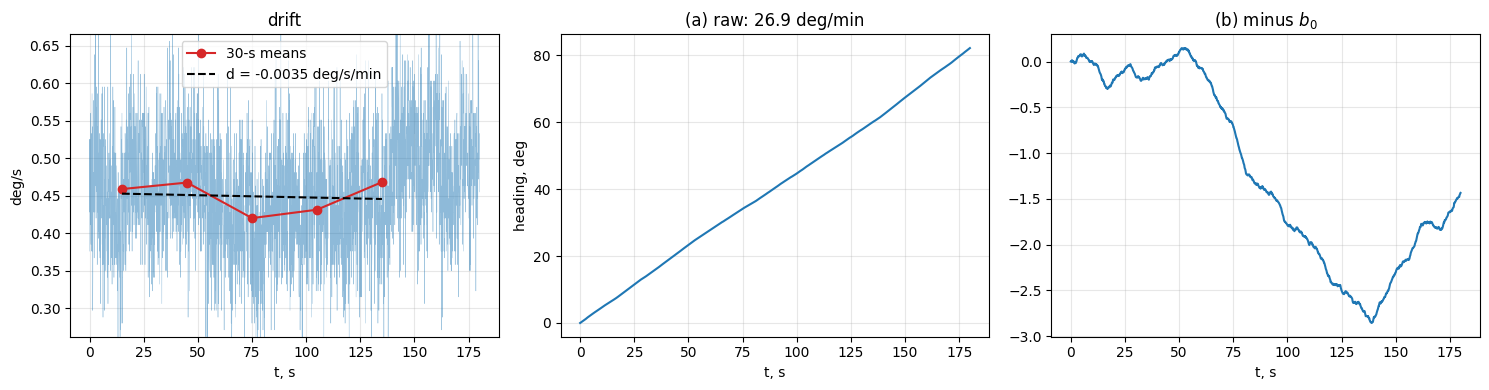

In [5]:
edges = np.arange(0, t_st[-1] + 1e-6, 30.0)
t_win = np.array([a + 15 for a in edges[:-1]])
b_win = np.array([omega_st[(t_st >= a) & (t_st < a + 30)].mean() for a in edges[:-1]])
d = np.polyfit(t_win / 60, b_win, 1)[0]
print("drift d = %.5f deg/s per min" % d)

theta_raw = cumtrapz(omega_st, t_st, initial=0)
theta_cal = cumtrapz(omega_st - b0_cal, t_st, initial=0)
slope_raw = np.polyfit(t_st / 60, theta_raw, 1)[0]
print("(a) uncorrected heading drift = %.2f deg/min   (b0·60 = %.2f deg/min)" % (slope_raw, b0 * 60))
for mnt in (1, 2, 3):
    k = min(np.searchsorted(t_st, 60 * mnt), len(t_st) - 1)
    print("(b) after %d min: raw %.2f deg, minus b0_cal %.2f deg" % (mnt, theta_raw[k], theta_cal[k]))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(t_st, omega_st, lw=0.3, alpha=0.5); ax[0].plot(t_win, b_win, "o-", color="C3", label="30-s means")
ax[0].plot(t_win, np.polyval(np.polyfit(t_win / 60, b_win, 1), t_win / 60), "k--", label="d = %.4f deg/s/min" % d)
ax[0].set_ylim(np.percentile(omega_st, 0.5), np.percentile(omega_st, 99.5)); ax[0].set_xlabel("t, s"); ax[0].set_ylabel("deg/s"); ax[0].legend(); ax[0].set_title("drift")
ax[1].plot(t_st, theta_raw); ax[1].set_xlabel("t, s"); ax[1].set_ylabel("heading, deg"); ax[1].set_title("(a) raw: %.1f deg/min" % slope_raw)
ax[2].plot(t_st, theta_cal); ax[2].set_xlabel("t, s"); ax[2].set_title("(b) minus $b_0$")
plt.tight_layout(); plt.show()

## 3. Measurement limits $\pm\omega_{max}$
During the fastest turns (amplitude 150 %, clipped to 100 %) the gyro may reach its limit.
Then many samples sit at exactly the same top value: a **flat top**. If there is no flat top, the robot was too slow and the numbers are only lower bounds (spin it by hand on an office chair to reach the limit).

+ω_max = +286.69 deg/s (141 samples at this value) -> flat top: SATURATED
-ω_max = -286.44 deg/s (141 samples at this value) -> flat top: SATURATED


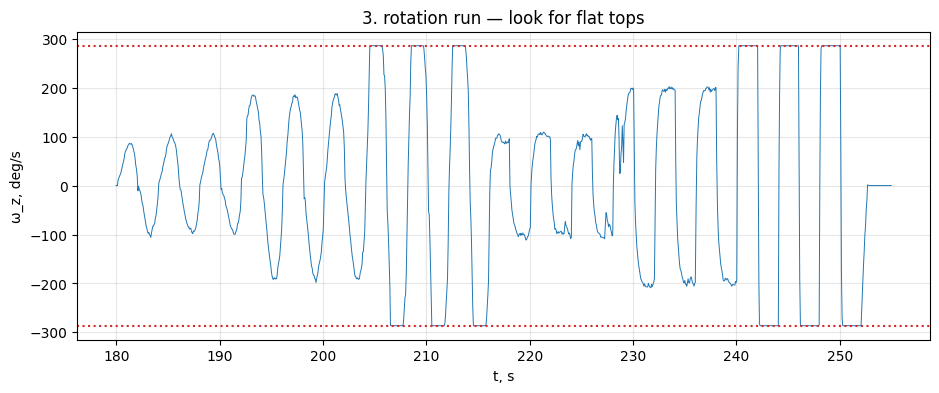

In [6]:
omega_rot = rot["omega_z"].values
omega_max_pos, omega_max_neg = omega_rot.max(), omega_rot.min()
n_pos = int(np.sum(omega_rot == omega_max_pos)); n_neg = int(np.sum(omega_rot == omega_max_neg))
print("+ω_max = %+.2f deg/s (%d samples at this value) -> %s" % (omega_max_pos, n_pos, "flat top: SATURATED" if n_pos >= 5 else "no flat top: lower bound"))
print("-ω_max = %+.2f deg/s (%d samples at this value) -> %s" % (omega_max_neg, n_neg, "flat top: SATURATED" if n_neg >= 5 else "no flat top: lower bound"))

plt.plot(rot.t, omega_rot, lw=0.7)
plt.axhline(omega_max_pos, color="C3", ls=":"); plt.axhline(omega_max_neg, color="C3", ls=":")
plt.xlabel("t, s"); plt.ylabel("ω_z, deg/s"); plt.title("3. rotation run — look for flat tops"); plt.show()

## 4. Noise $\sigma$
Static log with $b_0$ and the drift line removed: what is left is noise.
$\sigma$ = its standard deviation (this is **R = σ²** for the Kalman filter in Lab 12).
Histogram with a fitted Gaussian: is the noise Gaussian? Are there spikes?

σ = 0.0771 deg/s at 16 Hz  ->  R = σ² = 5.949e-03 (deg/s)²
outside 3σ: 0.28 % (Gaussian: 0.27 %), spikes > 5σ: 0


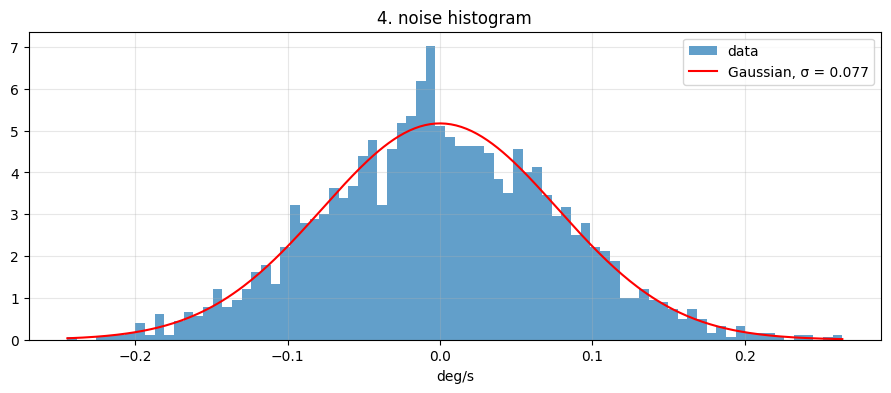

In [7]:
noise = omega_st - np.polyval(np.polyfit(t_st, omega_st, 1), t_st)
sigma = noise.std(ddof=1)
print("σ = %.4f deg/s at %.0f Hz  ->  R = σ² = %.3e (deg/s)²" % (sigma, fs, sigma ** 2))
print("outside 3σ: %.2f %% (Gaussian: 0.27 %%), spikes > 5σ: %d" % (100 * np.mean(np.abs(noise) > 3 * sigma), np.sum(np.abs(noise) > 5 * sigma)))

plt.hist(noise, bins=min(80, max(10, len(np.unique(noise)))), density=True, alpha=0.7, label="data")
x = np.linspace(noise.min(), noise.max(), 300)
plt.plot(x, stats.norm.pdf(x, 0, sigma), "r", label="Gaussian, σ = %.3f" % sigma)
plt.xlabel("deg/s"); plt.title("4. noise histogram"); plt.legend(); plt.show()

## Results

In [8]:
display(pd.DataFrame([
    ("Offset (bias)", "b0", "%.4f" % b0, "deg/s", "static mean, first %.0f s (±%.4f SE)" % (T_CAL_BASELINE, b0_se)),
    ("Offset, own method", "b0_cal", "%.4f" % b0_cal, "deg/s", "calibrate_gyro(), spikes removed"),
    ("Recommended calibration time", "T_cal_rec", "%.1f" % T_cal_rec, "s", "b0(T) flat within ±%.1f° / 3 min, 2·SE below it" % HEADING_TOL_DEG),
    ("Bias drift", "d", "%.5f" % d, "deg/s/min", "30-s window means"),
    ("Heading drift, uncorrected", "slope_raw", "%.2f" % slope_raw, "deg/min", "slope of integrated raw rate"),
    ("Heading error after 3 min (− b0_cal)", "theta_cal", "%.2f" % theta_cal[-1], "deg", "integral of (ω − b0_cal)"),
    ("Measurement limits", "omega_max_pos / omega_max_neg", "%+.1f / %+.1f" % (omega_max_pos, omega_max_neg), "deg/s",
     "max / min in rotation run (%s)" % ("flat top" if min(n_pos, n_neg) >= 5 else "no flat top: lower bound")),
    ("Noise std", "sigma", "%.4f" % sigma, "deg/s", "static 3 min, b0 + drift removed, %.0f Hz" % fs),
], columns=["Parameter", "Variable", "Value", "Unit", "Method"]))

,Parameter,Variable,Value,Unit,Method
0,Offset (bias),b0,0.4588,deg/s,"static mean, first 30 s (±0.0035 SE)"
1,"Offset, own method",b0_cal,0.4644,deg/s,"calibrate_gyro(), spikes removed"
2,Recommended calibration time,T_cal_rec,44.5,s,"b0(T) flat within ±1.0° / 3 min, 2·SE below it"
3,Bias drift,d,-0.00354,deg/s/min,30-s window means
4,"Heading drift, uncorrected",slope_raw,26.87,deg/min,slope of integrated raw rate
5,Heading error after 3 min (− b0_cal),theta_cal,-1.43,deg,integral of (ω − b0_cal)
6,Measurement limits,omega_max_pos / omega_max_neg,+286.7 / -286.4,deg/s,max / min in rotation run (flat top)
7,Noise std,sigma,0.0771,deg/s,"static 3 min, b0 + drift removed, 16 Hz"
